# LSC5 | T10: Transformer compacto, LOSO y preprocesamiento consciente de ausencias

**Versión optimizada del notebook T9 del equipo**, conservando la exploración, la geometría de 436 dimensiones, el espejo/TTA, validación LOSO interna/externa, las tres semillas, el análisis de errores, checkpoints y la inferencia final (deshabilitada).

### Cambios respecto a T9

1. **Se elimina el entrenamiento de SVM, TCN y la búsqueda de pesos de ensemble**. Solamente se entrena el Transformer ganador de T9.
2. **Se incorpora una alternativa de preprocesamiento** `PREPROCESS_MODE = 'mask_aware'` (nueva) y se conserva `legacy` como control **idéntico a T9** para comparar de manera justa.
3. El modo nuevo calcula la presencia de manos/rostro/cuerpo **antes** del remuestreo; rellena solo huecos cortos, evita promediar coordenadas válidas con ceros y mantiene las máscaras de presencia originales en el tiempo.
4. Diagnóstico de detección **solo en entrenamiento público**, por persona/vista/clase; métricas OOF y guardado seguro de pesos con escaladores Tensor.
5. **Aislamiento de experimentos**: directorio propio por variante y sin reusar cachés por defecto. No se interpreta la métrica LOSO como una estimación completamente independiente después de la selección repetida.

> ⚠️ **No afirmamos que el modo nuevo sea mejor**. Primero se compara `legacy` contra `mask_aware` en los *mismos folds y semillas*. No usar el test oficial para decidir. La corrección cambia características: los checkpoints de T9 **NO** son compatibles con la variante nueva sin reentrenar.

**Referencia histórica (NO calculada por este notebook):** T9 Transformer en 3 semillas y 436 características, accuracy LOSO OOF 0,9564 (1.076/1.125); M02 0,9947, M03 0,9280, M04 0,9467. Los números que genere T10 serán nuevos y se guardarán por separado.

## 0. Configuración reproducible

En Kaggle: **Add Input** con el conjunto de entrenamiento autorizado y **GPU T4**. No se necesitan los videos para esta versión.

**Experimento controlado:** ejecutar una vez con `PREPROCESS_MODE='legacy'`, y luego una segunda vez con `'mask_aware'`, manteniendo todo lo demás igual. Cada variante guarda resultados en una carpeta distinta. `QUICK_TEST=True` solo comprueba ejecución, **NO** sirve para medir desempeño. `TRAIN_FINAL_MODEL` se habilita una vez seleccionada la variante mediante LOSO; `RUN_FINAL_TEST_INFERENCE` permanece desactivado durante desarrollo.

In [1]:
from pathlib import Path
import os, re, json, math, random, time, copy, warnings, hashlib
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, classification_report
from IPython.display import display

try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs): return x

# ========= Configuración modificable =========
DATA_ROOT = Path('/kaggle/input')
TRAIN_LANDMARKS_DIR = '/kaggle/input/datasets/rutenco/train-l5c52/landmarks'  # Detección automática o Path('.../train/landmarks')
TEST_LANDMARKS_DIR = '/kaggle/input/datasets/rutenco/test-lsc5/landmarks'   # Solo durante inferencia final autorizada
SUBMISSION_TEMPLATE_PATH = '/kaggle/input/datasets/rutenco/template-lsc5/submission_template.csv'

PREPROCESS_MODE = 'mask_aware'  # 'legacy' reproduce T9; 'mask_aware' corrige ausencias
PRESENCE_MASK_MODE = 'keep'  # 'keep' o 'drop_hands' (ablación opcional SOLO para mask_aware)
MAX_INTERPOLATION_GAP = 3       # Fotogramas crudos consecutivos ausentes reparables entre observaciones válidas
PREPROCESS_VERSION = 't10_maskaware_v1_20261116'
ABLATE_WRIST_MIXED_Z = False # ACTIVAR LA ABLACIÓN DE PROFUNDIDAD
USE_436 = True
SEQ_LEN = 96
SEEDS = [42, 7, 123]
SEED = SEEDS[0]
BATCH_SIZE = 32
MAX_EPOCHS = 80
PATIENCE = 15
NUM_WORKERS = 2
USE_AMP = True
MIRROR_AUG = True
MIRROR_TTA = True
LR, WEIGHT_DECAY, DROPOUT = 5e-4, 1e-2, 0.3
D_MODEL, N_LAYERS, N_HEADS, FFN_DIM = 128, 2, 4, 256
HAND_DIM, BODY_DIM, FACE_DIM = 64, 32, 32

QUICK_TEST = False          # Solo prueba de ejecución: 1 semilla, 2 épocas; resultados NO comparables
TRAIN_FINAL_MODEL = True  # Habilitar SOLO después de elegir variante mediante LOSO
RUN_FINAL_TEST_INFERENCE = False

assert PREPROCESS_MODE in ('legacy', 'mask_aware')
assert PRESENCE_MASK_MODE in ('keep', 'drop_hands')
assert PREPROCESS_MODE != 'legacy' or PRESENCE_MASK_MODE == 'keep'
assert HAND_DIM + BODY_DIM + FACE_DIM == D_MODEL
if QUICK_TEST:
    SEEDS, MAX_EPOCHS, PATIENCE = [42], 2, 2

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CLASS_NAMES = [f'sign_{i:02d}' for i in range(1, 6)]
CLASS_TO_ID = {c: i for i, c in enumerate(CLASS_NAMES)}
ID_TO_CLASS = {i: c for c, i in CLASS_TO_ID.items()}

# El modo y la versión del código forman parte de la identidad del experimento.
CFG = dict(preprocess_mode=PREPROCESS_MODE, presence_mask_mode=PRESENCE_MASK_MODE, preprocess_version=PREPROCESS_VERSION,
           max_interpolation_gap=MAX_INTERPOLATION_GAP, use_436=USE_436, seq_len=SEQ_LEN,
           seeds=SEEDS, batch_size=BATCH_SIZE, max_epochs=MAX_EPOCHS, patience=PATIENCE,
           num_workers=NUM_WORKERS, mirror_aug=MIRROR_AUG, mirror_tta=MIRROR_TTA,
           lr=LR, weight_decay=WEIGHT_DECAY, dropout=DROPOUT,
           model=dict(d_model=D_MODEL, n_layers=N_LAYERS, heads=N_HEADS, ffn=FFN_DIM,
                      hand_dim=HAND_DIM, body_dim=BODY_DIM, face_dim=FACE_DIM), quick_test=QUICK_TEST)
CFG["ablate_wrist_mixed_z"] = ABLATE_WRIST_MIXED_Z
CFG_TAG = hashlib.sha256(json.dumps(CFG, sort_keys=True).encode('utf-8')).hexdigest()[:12]
OUT_DIR = Path('/kaggle/working') / f'lsc5_t10_transformer_{PREPROCESS_MODE}_{CFG_TAG}'
OUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything(SEEDS[0])
print('PyTorch:', torch.__version__, '| GPU:', torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else 'NO')
print('Modo:', PREPROCESS_MODE, '| 436 características:', USE_436, '| Semillas:', SEEDS)
print('Artefactos:', OUT_DIR)
if DEVICE.type != 'cuda': warnings.warn('GPU no detectada. Activar acelerador de Kaggle.')

PyTorch: 2.11.0+cu130 | GPU: Tesla T4
Modo: mask_aware | 436 características: True | Semillas: [42, 7, 123]
Artefactos: /kaggle/working/lsc5_t10_transformer_mask_aware_ba4092f8db67


## 1. Inventario del conjunto de entrenamiento

Se detecta únicamente una carpeta etiquetada con `sign_01...sign_05`. El participante reservado para test no debe aparecer en esta colección. Preservamos la lectura de metadatos del notebook T9.

In [2]:
def _class_dirs(path: Path):
    if not path.exists() or not path.is_dir():
        return []
    return [p for p in path.iterdir() if p.is_dir() and re.fullmatch(r'sign_\d{2}', p.name)]


def discover_train_landmarks(root=DATA_ROOT, override=None):
    """Encuentra train/landmarks sin entrar en carpetas de test."""
    if override is not None:
        p = Path(override)
        if not p.exists():
            raise FileNotFoundError(f'La ruta TRAIN_LANDMARKS_DIR no existe: {p}')
        return p

    if not root.exists():
        raise FileNotFoundError(f'No existe DATA_ROOT: {root}')

    candidates = []
    for p in root.rglob('landmarks'):
        if not p.is_dir():
            continue
        parts_lower = [part.lower() for part in p.parts]
        if 'test' in parts_lower:
            continue
        classes = _class_dirs(p)
        if len(classes) >= 5 and any(p.rglob('*.npy')):
            candidates.append(p)

    if not candidates:
        raise FileNotFoundError(
            'No encontré una carpeta train/landmarks con subcarpetas sign_01 ... sign_05. '
            'Define TRAIN_LANDMARKS_DIR manualmente.'
        )

    # Preferir una ruta que contenga explícitamente "train".
    candidates.sort(key=lambda p: ('train' not in [x.lower() for x in p.parts], len(str(p))))
    return candidates[0]


def parse_sample_metadata(path: Path):
    """Extrae etiqueta, participante, vista, cámara y grupo de ejecución."""
    stem = path.stem
    parent_match = re.fullmatch(r'(sign_\d{2})', path.parent.name)
    sign_match = re.search(r'(?:^|_)S(\d{2})(?:_|$)', stem)
    label = parent_match.group(1) if parent_match else (f'sign_{int(sign_match.group(1)):02d}' if sign_match else None)

    signer_match = re.search(r'(?:^|_)M(\d{2})(?:_|$)', stem)
    if signer_match is None:
        raise ValueError(f'No pude extraer participante M## del nombre: {path.name}')
    signer = f'M{signer_match.group(1)}'

    view_match = re.search(r'(?:^|_)V(\d{2})(?:_|$)', stem)
    camera_match = re.search(r'(?:^|_)C(\d{2})(?:_|$)', stem)
    clip_match = re.search(r'Clip(\d+)', stem, flags=re.IGNORECASE)

    if label not in CLASS_NAMES:
        raise ValueError(f'No pude identificar una clase sign_01 ... sign_05: {path}')

    # Agrupa las vistas/cámaras que comparten el mismo clip. Si no hay Clip, usa el archivo.
    group_id = f'{label}_{signer}_Clip{clip_match.group(1)}' if clip_match else stem
    return {
        'path': str(path),
        'video_id': stem,
        'label': label,
        'y': CLASS_TO_ID[label],
        'signer': signer,
        'view': f'V{view_match.group(1)}' if view_match else 'unknown',
        'camera': f'C{camera_match.group(1)}' if camera_match else 'unknown',
        'clip': clip_match.group(1) if clip_match else None,
        'group_id': group_id,
    }


TRAIN_LANDMARKS_DIR = discover_train_landmarks(DATA_ROOT, TRAIN_LANDMARKS_DIR)
records = []
for npy_path in sorted(TRAIN_LANDMARKS_DIR.rglob('*.npy')):
    # Esta carpeta debe ser exclusivamente el conjunto etiquetado de entrenamiento.
    records.append(parse_sample_metadata(npy_path))

metadata = pd.DataFrame(records)
# Integridad: ninguna ruta del inventario de entrenamiento puede pertenecer a una carpeta de test.
assert not any(part.lower() == 'test' for p in metadata['path'] for part in Path(p).parts), \
    'El inventario de entrenamiento contiene rutas de test.'
if metadata.empty:
    raise RuntimeError('No se encontraron archivos .npy en TRAIN_LANDMARKS_DIR.')

print('Carpeta de landmarks:', TRAIN_LANDMARKS_DIR)
print('Muestras etiquetadas:', len(metadata))
print('Participantes:', sorted(metadata.signer.unique()))
print('Clases:', sorted(metadata.label.unique()))
display(metadata.head())

Carpeta de landmarks: /kaggle/input/datasets/rutenco/train-l5c52/landmarks
Muestras etiquetadas: 1125
Participantes: ['M02', 'M03', 'M04']
Clases: ['sign_01', 'sign_02', 'sign_03', 'sign_04', 'sign_05']


,path,video_id,label,y,signer,view,camera,clip,group_id
0,/kaggle/input/datasets/rutenco/train-l5c52/lan...,S01_M02_V01_C01_Clip076,sign_01,0,M02,V01,C01,076,sign_01_M02_Clip076
1,/kaggle/input/datasets/rutenco/train-l5c52/lan...,S01_M02_V01_C01_Clip077,sign_01,0,M02,V01,C01,077,sign_01_M02_Clip077
2,/kaggle/input/datasets/rutenco/train-l5c52/lan...,S01_M02_V01_C01_Clip078,sign_01,0,M02,V01,C01,078,sign_01_M02_Clip078
3,/kaggle/input/datasets/rutenco/train-l5c52/lan...,S01_M02_V01_C01_Clip079,sign_01,0,M02,V01,C01,079,sign_01_M02_Clip079
4,/kaggle/input/datasets/rutenco/train-l5c52/lan...,S01_M02_V01_C01_Clip080,sign_01,0,M02,V01,C01,080,sign_01_M02_Clip080


## 2. Auditoría de archivos, participantes, clases y perspectivas

Verificación del equilibrio de clases, de vistas y de la disponibilidad de videos correspondientes si existen. Solo empleamos los datos públicos etiquetados.

Muestras por clase:


,n
label,
sign_01,225
sign_02,225
sign_03,225
sign_04,225
sign_05,225


Muestras por participante y clase:


label,sign_01,sign_02,sign_03,sign_04,sign_05
signer,,,,,
M02,75,75,75,75,75
M03,75,75,75,75,75
M04,75,75,75,75,75


Muestras por vista:


,n
view,
V01,375
V02,375
V03,375


Grupos de ejecución únicos: 1125
Archivos repetidos por video_id: 0


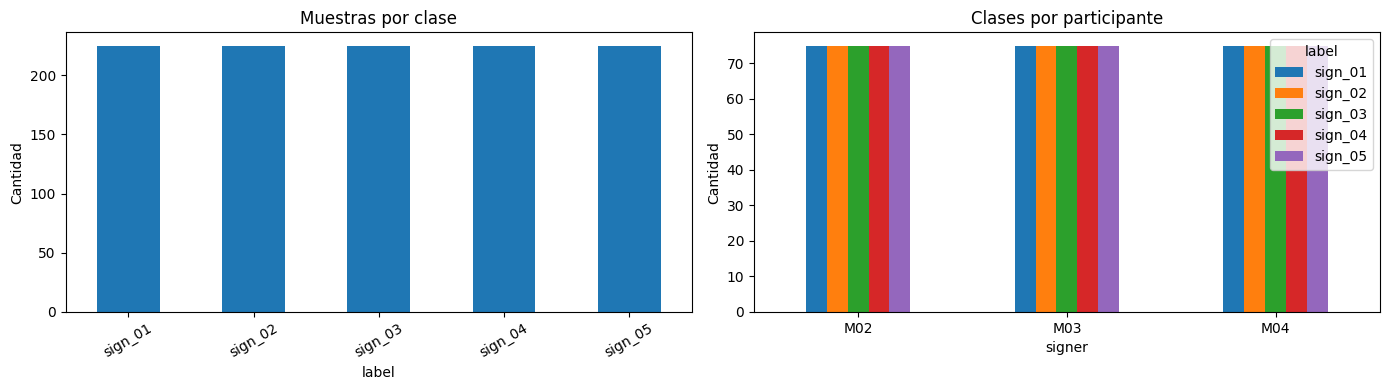

No encontré train/videos junto a train/landmarks; se continúa usando los .npy.


,label,file,shape,dtype,all_finite
0,sign_01,S01_M02_V01_C01_Clip076.npy,"(62, 1662)",float64,True
1,sign_01,S01_M02_V01_C01_Clip077.npy,"(83, 1662)",float64,True
2,sign_01,S01_M02_V01_C01_Clip078.npy,"(78, 1662)",float64,True
3,sign_02,S02_M02_V01_C02_Clip376.npy,"(69, 1662)",float64,True
4,sign_02,S02_M02_V01_C02_Clip377.npy,"(58, 1662)",float64,True
5,sign_02,S02_M02_V01_C02_Clip378.npy,"(77, 1662)",float64,True
6,sign_03,S03_M02_V01_C03_Clip676.npy,"(59, 1662)",float64,True
7,sign_03,S03_M02_V01_C03_Clip677.npy,"(72, 1662)",float64,True
8,sign_03,S03_M02_V01_C03_Clip678.npy,"(66, 1662)",float64,True
9,sign_04,S04_M02_V01_C04_Clip1000.npy,"(55, 1662)",float64,True


In [3]:
# El reto declara M01 como persona de test reservada. Nunca incluirla en desarrollo.
PUBLIC_SIGNERS_EXPECTED = ['M02', 'M03', 'M04']
found_signers = sorted(metadata['signer'].unique().tolist())
if found_signers != PUBLIC_SIGNERS_EXPECTED:
    raise RuntimeError(f'Firmantes públicos esperados {PUBLIC_SIGNERS_EXPECTED}; encontrados {found_signers}. '
                       'No utilizar test M01 en ninguna etapa de entrenamiento/validación.')
# Resumen de distribución
class_counts = metadata['label'].value_counts().reindex(CLASS_NAMES, fill_value=0)
signer_class = pd.crosstab(metadata['signer'], metadata['label']).reindex(columns=CLASS_NAMES, fill_value=0)
view_counts = metadata['view'].value_counts(dropna=False)

print('Muestras por clase:')
display(class_counts.rename('n').to_frame())
print('Muestras por participante y clase:')
display(signer_class)
print('Muestras por vista:')
display(view_counts.rename('n').to_frame())

# Conteos esperados según el Manual LSC5 para el split público de entrenamiento.
if len(metadata) != 1125:
    warnings.warn(f'Se esperaban 1125 landmarks públicos y se encontraron {len(metadata)}. Verifica la ruta.')
if metadata['signer'].nunique() > 3:
    raise ValueError('Se detectaron más de tres participantes en train. No incluyas el participante reservado para test.')
if not (signer_class == 75).all().all():
    warnings.warn('La distribución no coincide exactamente con 75 muestras por clase y participante; revisa el inventario.')
print('Grupos de ejecución únicos:', metadata['group_id'].nunique())
print('Archivos repetidos por video_id:', int(metadata['video_id'].duplicated().sum()))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
class_counts.plot(kind='bar', ax=axes[0], title='Muestras por clase')
axes[0].set_ylabel('Cantidad'); axes[0].tick_params(axis='x', rotation=30)
signer_class.plot(kind='bar', ax=axes[1], title='Clases por participante')
axes[1].set_ylabel('Cantidad'); axes[1].tick_params(axis='x', rotation=0)
plt.tight_layout(); plt.show()

# Comprobación de videos emparejados, si existe la carpeta hermana train/videos.
TRAIN_VIDEO_DIR = TRAIN_LANDMARKS_DIR.parent / 'videos'
if TRAIN_VIDEO_DIR.exists():
    video_stems = {p.stem for p in TRAIN_VIDEO_DIR.rglob('*.mp4')}
    metadata['has_video_pair'] = metadata['video_id'].isin(video_stems)
    print(f"Landmarks con video correspondiente: {metadata['has_video_pair'].sum()} / {len(metadata)}")
else:
    print('No encontré train/videos junto a train/landmarks; se continúa usando los .npy.')

# Inspección de forma y tipo en una muestra de archivos de cada clase.
shape_rows = []
for label in CLASS_NAMES:
    subset = metadata[metadata.label == label].head(3)
    for row in subset.itertuples():
        arr = np.load(row.path, allow_pickle=False)
        shape_rows.append({'label': label, 'file': Path(row.path).name,
                           'shape': arr.shape, 'dtype': str(arr.dtype),
                           'all_finite': bool(np.isfinite(arr).all())})
display(pd.DataFrame(shape_rows))

if metadata['signer'].nunique() != 3:
    warnings.warn(
        f"Se detectaron {metadata['signer'].nunique()} participantes etiquetados; "
        'el manual describe tres participantes públicos. Revisa que hayas agregado el split correcto.'
    )
if set(metadata['label'].unique()) != set(CLASS_NAMES):
    raise ValueError('Faltan clases. Revisa la ruta y la estructura del dataset.')

## 3. Landmarks, extracción base y normalización espacial

Se conserva la definición geométrica del T9: 200 características de posiciones/máscaras + 200 velocidades. Solo se añade un parámetro opcional para indicar máscaras **calculadas sobre el video crudo**, sin rederivarlas de coordenadas remuestreadas. Este cambio solo se activa en el modo nuevo.

In [4]:
# Índices de la representación descrita en el manual LSC5 / MediaPipe Holistic.
POSE_SLICE = slice(0, 132)
FACE_SLICE = slice(132, 1536)
LEFT_HAND_SLICE = slice(1536, 1599)
RIGHT_HAND_SLICE = slice(1599, 1662)

BODY_JOINTS = [11, 12, 13, 14, 15, 16, 23, 24]  # hombros, codos, muñecas y caderas
FACE_JOINTS = [1, 33, 133, 362, 263, 61, 291, 13, 14, 70, 300]
BASE_FEATURE_DIM = 200
FEATURE_DIM = BASE_FEATURE_DIM * 2  # posición + velocidad
MASK_FEATURES = [197, 198, 199, 397, 398, 399]


def load_landmark_array(path):
    """Carga un .npy y valida la forma esperada (T, 1662)."""
    arr = np.load(path, allow_pickle=False)
    arr = np.asarray(arr, dtype=np.float32)
    if arr.ndim != 2:
        raise ValueError(f'{path}: esperaba matriz 2D, recibí {arr.shape}')
    if arr.shape[1] != 1662 and arr.shape[0] == 1662:
        arr = arr.T
    if arr.shape[1] != 1662:
        raise ValueError(f'{path}: esperaba 1662 características por frame, recibí {arr.shape}')
    arr = np.nan_to_num(arr, nan=0.0, posinf=0.0, neginf=0.0)
    if len(arr) < 2:
        raise ValueError(f'{path}: secuencia demasiado corta ({len(arr)} frames)')
    return arr


def resample_frames(arr, target_len=SEQ_LEN):
    """Remuestreo lineal vectorizado a una longitud temporal fija."""
    n = len(arr)
    if n == target_len:
        return arr.astype(np.float32, copy=False)
    positions = np.linspace(0, n - 1, target_len, dtype=np.float32)
    lo = np.floor(positions).astype(np.int64)
    hi = np.minimum(lo + 1, n - 1)
    alpha = (positions - lo).astype(np.float32)[:, None]
    return (arr[lo] * (1.0 - alpha) + arr[hi] * alpha).astype(np.float32)


def landmarks_to_features(arr, target_len=SEQ_LEN, presence_override=None, already_resampled=False):
    """Construye (T,400). presence_override=(T,3) con presencia observada EN CRUDO.

    En modo legacy se mantiene exactamente la función original de T9.
    """
    if already_resampled:
        assert len(arr) == target_len
    else:
        arr = resample_frames(arr, target_len)
    if presence_override is not None:
        presence_override = np.asarray(presence_override, dtype=np.float32)
        assert presence_override.shape == (target_len, 3)
    t = len(arr)

    pose = arr[:, POSE_SLICE].reshape(t, 33, 4)
    face = arr[:, FACE_SLICE].reshape(t, 468, 3)
    left_hand = arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3)
    right_hand = arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3)

    # Centro del torso y escala robusta por video: distancia entre hombros.
    left_shoulder = pose[:, 11, :3]
    right_shoulder = pose[:, 12, :3]
    torso_center = (left_shoulder + right_shoulder) / 2.0
    shoulder_width = np.linalg.norm(left_shoulder[:, :2] - right_shoulder[:, :2], axis=1)
    valid_widths = shoulder_width[shoulder_width > 1e-4]
    body_scale = float(np.median(valid_widths)) if len(valid_widths) else 1.0
    body_scale = max(body_scale, 1e-3)

    def hand_features(hand, observed=None):
        geometric_present = (np.max(np.abs(hand), axis=(1, 2)) > 1e-6).astype(np.float32)
        present = geometric_present if observed is None else observed
        wrist = hand[:, 0, :]
        local = (hand - wrist[:, None, :]) / body_scale
        global_wrist = (wrist - torso_center) / body_scale
        # Las posiciones reconstruidas son útiles aun si la observación fue ausente:
        # ponemos a cero solo geometría realmente inexistente.
        local[geometric_present == 0] = 0.0
        global_wrist[geometric_present == 0] = 0.0
        return local.reshape(t, -1), global_wrist, present

    left_local, left_wrist, left_present = hand_features(left_hand, None if presence_override is None else presence_override[:, 0])
    right_local, right_wrist, right_present = hand_features(right_hand, None if presence_override is None else presence_override[:, 1])

    # Postura relativa al torso; se conserva visibilidad como cuarta característica.
    body_xyz = (pose[:, BODY_JOINTS, :3] - torso_center[:, None, :]) / body_scale
    body_visibility = pose[:, BODY_JOINTS, 3:4]
    body_features = np.concatenate([body_xyz, body_visibility], axis=2).reshape(t, -1)

    # Rasgos faciales compactos. Se conservan cambios locales respecto a la nariz.
    selected_face = face[:, FACE_JOINTS, :]
    nose = face[:, 1, :]
    eye_width = np.linalg.norm(face[:, 33, :2] - face[:, 263, :2], axis=1)
    valid_eye_widths = eye_width[eye_width > 1e-4]
    face_scale = float(np.median(valid_eye_widths)) if len(valid_eye_widths) else 1.0
    face_scale = max(face_scale, 1e-3)
    face_present = (np.max(np.abs(face), axis=(1, 2)) > 1e-6).astype(np.float32)
    face_local = (selected_face - nose[:, None, :]) / face_scale
    face_local[face_present == 0] = 0.0
    if presence_override is not None:
        face_present = presence_override[:, 2]
    face_features = face_local.reshape(t, -1)

    # 126 mano + 6 trayectorias de muñeca + 32 cuerpo + 33 rostro + 3 máscaras = 200.
    base = np.concatenate([
        left_local, right_local,
        left_wrist, right_wrist,
        body_features, face_features,
        left_present[:, None], right_present[:, None], face_present[:, None]
    ], axis=1).astype(np.float32)

    if base.shape[1] != BASE_FEATURE_DIM:
        raise RuntimeError(f'Dimensión base inesperada: {base.shape[1]}')

    # Diferencias frame a frame. Las máscaras no representan velocidad.
    velocity = np.diff(base, axis=0, prepend=base[:1]).astype(np.float32)
    velocity[:, -3:] = 0.0
    features = np.concatenate([base, velocity], axis=1).astype(np.float32)
    if features.shape != (target_len, FEATURE_DIM):
        raise RuntimeError(f'Dimensión final inesperada: {features.shape}')
    return np.nan_to_num(features, nan=0.0, posinf=0.0, neginf=0.0)


print('Dimensión por frame:', FEATURE_DIM)
print('Máscaras de presencia:', MASK_FEATURES)

# Prueba rápida de procesamiento con un archivo real.
example_path = Path(metadata.iloc[0]['path'])
example_raw = load_landmark_array(example_path)
example_features = landmarks_to_features(example_raw)
print('Archivo de ejemplo:', example_path.name)
print('Forma original:', example_raw.shape)
print('Forma procesada:', example_features.shape)
print('Valores finitos:', np.isfinite(example_features).all())

Dimensión por frame: 400
Máscaras de presencia: [197, 198, 199, 397, 398, 399]
Archivo de ejemplo: S01_M02_V01_C01_Clip076.npy
Forma original: (62, 1662)
Forma procesada: (96, 400)
Valores finitos: True


### 3a. Espejo anatómico (se preserva T9)

Transformación por muestra: refleja el eje `x` y permuta manos y articulaciones izquierda/derecha. Se comprueba que aplicarla dos veces reproduce la señal original.

In [5]:
# 3b. Espejo (lateralidad). Transformacion determinista aplicada a cada muestra por separado.
PAIRS = [(1,4),(2,5),(3,6),(7,8),(9,10),(11,12),(13,14),(15,16),(17,18),(19,20),(21,22),(23,24),(25,26),(27,28),(29,30),(31,32)]
FACE_PAIRS = [(33,263),(133,362),(61,291),(70,300)]  # solo los puntos de rostro que usa el modelo


def _flipx(block):
    """x -> 1-x solo donde el punto existe (los ceros significan 'no detectado')."""
    block = block.copy()
    present = np.abs(block).max(axis=2) > 1e-6
    block[..., 0] = np.where(present, 1.0 - block[..., 0], 0.0)
    return block


def mirror_raw(arr):
    t = len(arr)
    pose = _flipx(arr[:, POSE_SLICE].reshape(t, 33, 4))
    face = _flipx(arr[:, FACE_SLICE].reshape(t, 468, 3))
    lh = _flipx(arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3))
    rh = _flipx(arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3))
    for i, j in PAIRS:
        pose[:, [i, j]] = pose[:, [j, i]]
    for i, j in FACE_PAIRS:
        face[:, [i, j]] = face[:, [j, i]]
    # al espejar, la mano izquierda pasa a ser la derecha y viceversa
    return np.concatenate([pose.reshape(t, -1), face.reshape(t, -1),
                           rh.reshape(t, -1), lh.reshape(t, -1)], axis=1).astype(np.float32)


_ex = load_landmark_array(example_path)
assert np.allclose(mirror_raw(mirror_raw(_ex)), _ex, atol=1e-5), 'espejar dos veces debe devolver el original'
print('Espejo OK (doble espejo = original).')

Espejo OK (doble espejo = original).


### 3b. Características adicionales (36) y modo original T9

Se conservan exactamente los ángulos de dedos y distancias de T9, así como `full_features_legacy`, para que la comparación de las variantes no confunda un cambio de red con el procesamiento.

In [6]:
# 3c. Características nuevas (36): ángulos de dedos + distancias mano-rostro / mano-torso.
EXTRA_DIM = 36
INPUT_DIM = FEATURE_DIM + (EXTRA_DIM if USE_436 else 0)   # FEATURE_DIM = 400 (definido en 3)
FINGER_CHAINS = [(0, 1, 2, 3, 4), (0, 5, 6, 7, 8), (0, 9, 10, 11, 12), (0, 13, 14, 15, 16), (0, 17, 18, 19, 20)]


def _joint_angles(hand):
    """hand: (T, 21, 3) -> (T, 15): angulo en cada articulacion de cada dedo, dividido por pi."""
    out = []
    for chain in FINGER_CHAINS:
        for k in range(1, 4):
            p_prev, p_joint, p_next = hand[:, chain[k - 1]], hand[:, chain[k]], hand[:, chain[k + 1]]
            v1, v2 = p_prev - p_joint, p_next - p_joint
            denom = np.maximum(np.linalg.norm(v1, axis=1) * np.linalg.norm(v2, axis=1), 1e-6)
            cos = np.clip(np.sum(v1 * v2, axis=1) / denom, -1.0, 1.0)
            out.append(np.arccos(cos) / np.pi)
    return np.stack(out, axis=1)


def extra_features(arr):
    """arr: (T, 1662) crudo -> (T, 36). Orden: ang_izq(15), ang_der(15), dist_izq(3), dist_der(3)."""
    t = len(arr)
    pose = arr[:, POSE_SLICE].reshape(t, 33, 4)
    face = arr[:, FACE_SLICE].reshape(t, 468, 3)
    hands = [arr[:, LEFT_HAND_SLICE].reshape(t, 21, 3), arr[:, RIGHT_HAND_SLICE].reshape(t, 21, 3)]

    widths = np.linalg.norm(pose[:, 11, :2] - pose[:, 12, :2], axis=1)
    valid = widths[widths > 1e-4]
    scale = max(float(np.median(valid)) if len(valid) else 1.0, 1e-3)
    chest = pose[:, [11, 12, 23, 24], :2].mean(axis=1)            # centro del torso (hombros + caderas)
    face_present = np.max(np.abs(face), axis=(1, 2)) > 1e-6
    nose = face[:, 1, :2]
    mouth = (face[:, 13, :2] + face[:, 14, :2]) / 2.0

    blocks_ang, blocks_dist = [], []
    for hand in hands:
        present = np.max(np.abs(hand), axis=(1, 2)) > 1e-6
        ang = _joint_angles(hand)
        wrist = hand[:, 0, :2]
        dist = np.stack([np.linalg.norm(wrist - nose, axis=1),
                         np.linalg.norm(wrist - mouth, axis=1),
                         np.linalg.norm(wrist - chest, axis=1)], axis=1) / scale
        dist[~face_present, :2] = 0.0
        ang[~present] = 0.0
        dist[~present] = 0.0
        blocks_ang.append(ang)
        blocks_dist.append(dist)
    out = np.concatenate([blocks_ang[0], blocks_ang[1], blocks_dist[0], blocks_dist[1]], axis=1)
    return np.nan_to_num(out, nan=0.0, posinf=0.0, neginf=0.0).astype(np.float32)

### 3c. Corrección: presencia **antes** del remuestreo

**Problema en T9:** una mano ausente se guarda con ceros. Al interpolar primero las 1.662 columnas, se promedian ceros con puntos reales y se crean coordenadas artificiales; después se infiere presencia de esos valores alterados.

**Modo nuevo (`mask_aware`):**

1. Detectar presencia por segmento anatómico sobre frames originales.
2. Reconstruir solo huecos internos cortos entre observaciones válidas (como máximo `MAX_INTERPOLATION_GAP`). Nunca inventar una seña en ausencias largas.
3. Remuestrear cada bloque sin mezclar coordenadas válidas con ceros cuando un extremo no está disponible.
4. Remuestrear las **máscaras originales** por vecino más cercano (sin falso positivo por interpolación).
5. Conservar la máscara de observación aunque exista una coordenada reconstruida, para que el modelo sepa cuándo un punto fue imputado.

Se mantiene el mismo tamaño de entrada: 436 características y la misma arquitectura Transformer. Esto permite medir si la corrección mejora o empeora el reconocimiento sin modificar la red. Importante: es una hipótesis experimental, no una mejora demostrada.

In [7]:
def raw_presence_masks(raw):
    """Retorna 4 flags (pose, rostro, mano izq, mano der) por frame ORIGINAL."""
    t = len(raw)
    pose = raw[:, POSE_SLICE].reshape(t, 33, 4)
    face = raw[:, FACE_SLICE].reshape(t, 468, 3)
    lh = raw[:, LEFT_HAND_SLICE].reshape(t, 21, 3)
    rh = raw[:, RIGHT_HAND_SLICE].reshape(t, 21, 3)
    return np.stack([
        np.max(np.abs(pose[:, :, :3]), axis=(1, 2)) > 1e-6,
        np.max(np.abs(face), axis=(1, 2)) > 1e-6,
        np.max(np.abs(lh), axis=(1, 2)) > 1e-6,
        np.max(np.abs(rh), axis=(1, 2)) > 1e-6,
    ], axis=1)


def fill_short_missing_runs(block, observed, max_gap=MAX_INTERPOLATION_GAP):
    """Imputa SOLO huecos interiores de hasta max_gap frames usando los dos extremos válidos.

    Devuelve (bloque corregido, usable). Una máscara 'observed' separada NO se modifica.
    """
    block = np.asarray(block, dtype=np.float32)
    observed = np.asarray(observed, dtype=bool)
    out = block.copy()
    usable = observed.copy()
    valid_indices = np.flatnonzero(observed)
    for a, b in zip(valid_indices[:-1], valid_indices[1:]):
        count = int(b - a - 1)
        if 0 < count <= max_gap:
            for i in range(a + 1, b):
                w = (i - a) / (b - a)
                out[i] = (1.0 - w) * out[a] + w * out[b]
                usable[i] = True
    return out, usable


def resample_masked_block(block, usable, positions):
    """Interpola pares utilizables; evita mezclas entre un frame válido y un cero ausente."""
    lo = np.floor(positions).astype(np.int64)
    hi = np.minimum(lo + 1, len(block) - 1)
    alpha = (positions - lo).astype(np.float32)
    shape = (len(positions),) + (1,) * (block.ndim - 1)
    w = alpha.reshape(shape)
    mix = (1 - w) * block[lo] + w * block[hi]
    both = usable[lo] & usable[hi]
    choose_lo = usable[lo] & (~usable[hi]) & (alpha < 0.5)
    choose_hi = usable[hi] & (~usable[lo]) & (alpha >= 0.5)
    out = np.zeros_like(mix)
    out[both] = mix[both]
    out[choose_lo] = block[lo[choose_lo]]
    out[choose_hi] = block[hi[choose_hi]]
    return out.astype(np.float32)


def resample_landmarks_mask_aware(raw, target_len=SEQ_LEN):
    """Retorna landmarks remuestreados y las máscaras observadas originales (T,3)."""
    raw = np.asarray(raw, dtype=np.float32)
    observed = raw_presence_masks(raw)  # SIEMPRE sobre video crudo sin interpolar
    positions = np.linspace(0, len(raw) - 1, target_len, dtype=np.float32)
    nearest = np.floor(positions + 0.5).astype(np.int64)
    nearest = np.clip(nearest, 0, len(raw) - 1)

    specs = [(POSE_SLICE, 0), (FACE_SLICE, 1), (LEFT_HAND_SLICE, 2), (RIGHT_HAND_SLICE, 3)]
    result = np.zeros((target_len, 1662), dtype=np.float32)
    for sl, j in specs:
        repaired, usable = fill_short_missing_runs(raw[:, sl], observed[:, j])
        result[:, sl] = resample_masked_block(repaired, usable, positions)

    # Orden de máscaras de la arquitectura: mano izquierda, derecha, rostro.
    original_masks = observed[nearest][:, [2, 3, 1]].astype(np.float32)
    return result, original_masks


def full_features(raw, seq_len=SEQ_LEN, preprocess_mode=PREPROCESS_MODE):
    """Genera las características temporales del Transformer."""

    # 1. Preprocesamiento
    if preprocess_mode == 'legacy':
        arr = resample_frames(raw, seq_len)
        base = landmarks_to_features(arr, seq_len)

    elif preprocess_mode == 'mask_aware':
        arr, original_masks = resample_landmarks_mask_aware(
            raw, seq_len
        )

        base = landmarks_to_features(
            arr,
            seq_len,
            presence_override=original_masks,
            already_resampled=True
        )

    else:
        raise ValueError(
            f'PREPROCESS_MODE desconocido: {preprocess_mode}'
        )

    # 2. Características adicionales
    if USE_436:
        out = np.concatenate(
            [base, extra_features(arr)], axis=1
        )
    else:
        out = base

    out = np.nan_to_num(
        out, nan=0.0, posinf=0.0, neginf=0.0
    ).astype(np.float32)

    # 3. Ablación de máscaras (T10-B)
    if (
        preprocess_mode == 'mask_aware'
        and PRESENCE_MASK_MODE == 'drop_hands'
    ):
        out[:, [197, 198, 397, 398]] = 0.0

    # 4. Ablación de profundidad (T10-D)
    if ABLATE_WRIST_MIXED_Z:
        out[:, [128, 131, 328, 331]] = 0.0

    # 5. Verificaciones
    assert out.shape == (seq_len, INPUT_DIM)
    assert np.isfinite(out).all()

    return out

### 3d. Pruebas de integridad: legado, ausencia de manos y espejo

Se realizan pruebas sintéticas y un ejemplo real del entrenamiento. **No se lee el test oficial**. En particular, una mano ausente en los frames originales no debe volverse "presente" solo por interpolación.

In [8]:
def run_preprocessing_unit_tests():
    raw = np.zeros((7, 1662), dtype=np.float32)
    pose = raw[:, POSE_SLICE].reshape(7, 33, 4)
    pose[:, 11, :2] = [0.4, 0.4]
    pose[:, 12, :2] = [0.6, 0.4]
    face = raw[:, FACE_SLICE].reshape(7, 468, 3)
    face[:, 1, :2] = [0.5, 0.2]
    face[:, 33, :2] = [0.45, 0.2]
    face[:, 263, :2] = [0.55, 0.2]
    lh = raw[:, LEFT_HAND_SLICE].reshape(7, 21, 3)
    # Ausencia interna corta, frames 2 y 3, entre 1 y 4.
    lh[[0, 1, 4, 5, 6], :, 0] = 0.3
    lh[[0, 1, 4, 5, 6], :, 1] = 0.5
    observed = raw_presence_masks(raw)
    assert observed[:, 2].tolist() == [True, True, False, False, True, True, True]
    resampled, masks = resample_landmarks_mask_aware(raw, target_len=7)
    assert masks[:, 0].tolist() == [1., 1., 0., 0., 1., 1., 1.]
    assert np.abs(resampled[2:4, LEFT_HAND_SLICE]).sum() > 0, 'No se reconstruyó hueco corto'
    assert np.array_equal(raw_presence_masks(raw), observed), 'Se mutaron datos originales'
    feat_new = full_features(raw, 7, 'mask_aware')
    if PRESENCE_MASK_MODE == 'keep':
        assert np.allclose(feat_new[:, 197], masks[:, 0])
        assert np.allclose(feat_new[:, 198], masks[:, 1])
    else:
        assert np.allclose(feat_new[:, [197,198,397,398]], 0.0)
    assert np.allclose(feat_new[:, 199], masks[:, 2])
    feat_old = full_features(raw, 7, 'legacy')
    old_manual = landmarks_to_features(resample_frames(raw, 7), 7)
    if USE_436: old_manual = np.concatenate([old_manual, extra_features(resample_frames(raw, 7))], axis=1)
    assert np.allclose(feat_old, old_manual), 'Modo legacy no coincide con T9'
    assert np.all(np.isfinite(feat_new))
    assert np.allclose(mirror_raw(mirror_raw(raw)), raw)

    # Ausencia larga: NO inventar coordenadas dentro del hueco.
    long_raw = raw.copy()
    long_raw[1:6, LEFT_HAND_SLICE] = 0
    out_long, mask_long = resample_landmarks_mask_aware(long_raw, 7)
    assert np.allclose(out_long[1:6, LEFT_HAND_SLICE], 0)
    assert np.all(mask_long[1:6, 0] == 0)
    print('Pruebas sintéticas OK: legacy, máscaras crudas, reconstrucción corta y huecos largos.')

run_preprocessing_unit_tests()
_f = full_features(example_raw)
print('Archivo real:', example_path.name, '| Características:', _f.shape,
      '| Finitos:', bool(np.isfinite(_f).all()), '| Modo:', PREPROCESS_MODE)

Pruebas sintéticas OK: legacy, máscaras crudas, reconstrucción corta y huecos largos.
Archivo real: S01_M02_V01_C01_Clip076.npy | Características: (96, 436) | Finitos: True | Modo: mask_aware


## 4. Diagnóstico en entrenamiento: disponibilidad de manos por vista/clase

El experimento T9 mostró errores especialmente concentrados en `sign_05` para M03/V01 y M04/V02. Medimos la fracción de detección **sobre frames originales**, sin leer test ni utilizar esta información para deducir etiquetas ocultas.

In [9]:
def diagnose_public_presence(meta_df):
    rows = []
    for r in tqdm(meta_df.itertuples(index=False), total=len(meta_df), desc='Calidad de detección (train)'):
        raw = load_landmark_array(r.path)
        pres = raw_presence_masks(raw)
        rows.append({'video_id': r.video_id, 'signer': r.signer, 'view': r.view,
                     'label': r.label, 'frames': len(raw),
                     'pose_seen': float(pres[:, 0].mean()), 'face_seen': float(pres[:, 1].mean()),
                     'left_seen': float(pres[:, 2].mean()), 'right_seen': float(pres[:, 3].mean())})
    return pd.DataFrame(rows)

presence_df = diagnose_public_presence(metadata)
presence_df.to_csv(OUT_DIR / 'public_presence_diagnostics.csv', index=False)
print('Detección media por participante:')
display(presence_df.groupby('signer')[['left_seen', 'right_seen', 'face_seen']].mean().round(3))
print('Detección por participante/vista en sign_05:')
display(presence_df[presence_df.label == 'sign_05'].
        groupby(['signer','view'])[['left_seen','right_seen','face_seen','frames']].mean().round(3))
print('Estos diagnósticos no implican causalidad y no constituyen información de test.')

Calidad de detección (train):   0%|          | 0/1125 [00:00<?, ?it/s]

Detección media por participante:


,left_seen,right_seen,face_seen
signer,,,
M02,0.583,0.191,0.990
M03,0.264,0.600,0.986
M04,0.283,0.637,0.990


Detección por participante/vista en sign_05:


left_seen  right_seen  face_seen  frames
signer view                                          
M02    V01       0.684       0.000      1.000   49.40
       V02       0.578       0.231      1.000   48.72
       V03       0.551       0.001      0.938   48.20
M03    V01       0.999       0.647      1.000   48.40
       V02       0.000       0.512      1.000   46.68
       V03       0.285       0.491      1.000   44.84
M04    V01       0.000       0.598      1.000   57.56
       V02       0.980       0.981      0.991   53.64
       V03       0.097       0.505      1.000   59.68

Estos diagnósticos no implican causalidad y no constituyen información de test.


## 5. Procesar las 1.125 secuencias y su espejo

La matriz final conserva el orden de metadatos y las 436 dimensiones de T9. El modo se fija **antes** de ejecutar los folds y no depende del participante de validación ni del test.

In [10]:
def build_feature_tensor(meta_df, mirror=False, seq_len=SEQ_LEN):
    """Procesa las muestras etiquetadas (opcionalmente espejadas) y devuelve X."""
    sequences = []
    desc = 'Espejando landmarks' if mirror else 'Procesando landmarks'
    for row in tqdm(meta_df.itertuples(index=False), total=len(meta_df), desc=desc):
        raw = load_landmark_array(row.path)
        if mirror:
            raw = mirror_raw(raw)   # transformacion determinista por muestra
        sequences.append(full_features(raw, seq_len))
    return np.stack(sequences).astype(np.float32)

X = build_feature_tensor(metadata)
X_mirror = build_feature_tensor(metadata, mirror=True)
y = metadata['y'].to_numpy(dtype=np.int64)
signer_values_all = metadata['signer'].to_numpy()
SIGNERS = sorted(metadata['signer'].unique())
assert X.shape[2] == INPUT_DIM and X_mirror.shape == X.shape

print('X:', X.shape, X.dtype, '| X_mirror:', X_mirror.shape)
print('Uso aproximado de memoria (MB):', round((X.nbytes + X_mirror.nbytes) / 1024**2, 1))
print('Distribución de etiquetas:', Counter(y.tolist()))
metadata.to_csv(OUT_DIR / 'train_metadata.csv', index=False)

Procesando landmarks:   0%|          | 0/1125 [00:00<?, ?it/s]

Espejando landmarks:   0%|          | 0/1125 [00:00<?, ?it/s]

X: (1125, 96, 436) float32 | X_mirror: (1125, 96, 436)
Uso aproximado de memoria (MB): 359.3
Distribución de etiquetas: Counter({0: 225, 1: 225, 2: 225, 3: 225, 4: 225})


## 6. Escalado y métricas (Accuracy Top-1 y macro-F1)

El escalador de cada modelo se aprende exclusivamente con las muestras del entrenamiento de su fold, incluidas las copias de espejo autorizadas. No se reutiliza un escalador de otro fold.

In [11]:
def fit_sequence_scaler(X_train):
    """Ajusta media y desviación por característica usando solo X_train."""
    flat = X_train.reshape(-1, X_train.shape[-1]).astype(np.float64)
    mean = flat.mean(axis=0).astype(np.float32)
    std = flat.std(axis=0).astype(np.float32)
    std[std < 1e-5] = 1.0
    return {'mean': mean, 'std': std}


def apply_sequence_scaler(X_data, scaler):
    return ((X_data - scaler['mean'][None, None, :]) /
            scaler['std'][None, None, :]).astype(np.float32)


def calculate_metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, average='macro', zero_division=0)),
    }


def print_confusion(y_true, y_pred, title='Matriz de confusión'):
    cm = confusion_matrix(y_true, y_pred, labels=list(range(len(CLASS_NAMES))))
    fig, ax = plt.subplots(figsize=(6, 5))
    im = ax.imshow(cm, cmap='Blues')
    ax.set_title(title)
    ax.set_xlabel('Predicción'); ax.set_ylabel('Etiqueta real')
    ax.set_xticks(range(5), CLASS_NAMES, rotation=35, ha='right')
    ax.set_yticks(range(5), CLASS_NAMES)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center')
    fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout(); plt.show()
    return cm

# Diagnóstico: la longitud temporal ya quedó homogeneizada.
print('Forma de X:', X.shape)
print('Rango global de características:', float(X.min()), 'a', float(X.max()))

Forma de X: (1125, 96, 436)
Rango global de características: -6.649068832397461 a 5.758484840393066


## 7. Arquitectura única: Transformer anatómico compacto (T9)

Se mantienen exactamente las ramas de manos/cuerpo/rostro, proyecciones, posición aprendible, dos capas de atención, pooling y clasificador de T9; con ello, **la arquitectura es una variable controlada**.

In [12]:
# Índices (orden de landmarks_to_features): manos 0:132, cuerpo 132:164, rostro 164:197, máscaras 197:200,
# velocidades +200. Las 36 características nuevas ocupan 400:436 y se asignan a la rama de manos.
HAND_STREAM_IDX = list(range(0, 132)) + list(range(200, 332)) + [197, 198] + (list(range(400, 436)) if USE_436 else [])
BODY_STREAM_IDX = list(range(132, 164)) + list(range(332, 364))
FACE_STREAM_IDX = list(range(164, 197)) + list(range(364, 397)) + [199]
_all_idx = HAND_STREAM_IDX + BODY_STREAM_IDX + FACE_STREAM_IDX
assert len(set(_all_idx)) == len(_all_idx) and max(_all_idx) < INPUT_DIM


def _branch(n_in, n_out):
    """Proyección de una rama anatómica: Linear -> LayerNorm -> GELU."""
    return nn.Sequential(nn.Linear(n_in, n_out), nn.LayerNorm(n_out), nn.GELU())


class LSC5_Transformer(nn.Module):
    """Transformer compacto: ramas anatómicas + posición aprendible + encoder + pooling temporal."""
    def __init__(self, input_dim=INPUT_DIM, seq_len=SEQ_LEN, d_model=D_MODEL, nhead=N_HEADS,
                 num_layers=N_LAYERS, dim_feedforward=FFN_DIM, dropout=0.3, num_classes=5):
        super().__init__()
        if input_dim != INPUT_DIM:
            raise ValueError(f'input_dim debe ser {INPUT_DIM}, recibí {input_dim}')
        self.register_buffer('hand_idx', torch.tensor(HAND_STREAM_IDX, dtype=torch.long))
        self.register_buffer('body_idx', torch.tensor(BODY_STREAM_IDX, dtype=torch.long))
        self.register_buffer('face_idx', torch.tensor(FACE_STREAM_IDX, dtype=torch.long))
        self.hand_proj = _branch(len(HAND_STREAM_IDX), HAND_DIM)
        self.body_proj = _branch(len(BODY_STREAM_IDX), BODY_DIM)
        self.face_proj = _branch(len(FACE_STREAM_IDX), FACE_DIM)
        self.fusion_norm = nn.LayerNorm(d_model)
        self.pos_embed = nn.Parameter(torch.zeros(1, seq_len, d_model))
        nn.init.trunc_normal_(self.pos_embed, std=0.02)
        self.embed_dropout = nn.Dropout(dropout)
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=d_model, nhead=nhead, dim_feedforward=dim_feedforward,
            dropout=dropout, activation='gelu', batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(encoder_layer, num_layers=num_layers,
                                             norm=nn.LayerNorm(d_model), enable_nested_tensor=False)
        self.attn_pool = nn.Linear(d_model, 1)
        self.classifier = nn.Sequential(nn.LayerNorm(d_model * 2), nn.Dropout(dropout),
                                        nn.Linear(d_model * 2, num_classes))

    def forward(self, x):
        if x.shape[1] != self.pos_embed.shape[1]:
            raise ValueError(f'Se esperaban {self.pos_embed.shape[1]} frames y llegaron {x.shape[1]}.')
        tokens = torch.cat([self.hand_proj(x.index_select(2, self.hand_idx)),
                            self.body_proj(x.index_select(2, self.body_idx)),
                            self.face_proj(x.index_select(2, self.face_idx))], dim=-1)
        tokens = self.embed_dropout(self.fusion_norm(tokens) + self.pos_embed)
        features = self.encoder(tokens)
        weights = torch.softmax(self.attn_pool(features), dim=1)
        attended = torch.sum(features * weights, dim=1)
        return self.classifier(torch.cat([attended, features.mean(dim=1)], dim=1))




def make_model(model_name='transformer'):
    if model_name != 'transformer':
        raise ValueError('T10 solo entrena Transformer')
    return LSC5_Transformer(dropout=DROPOUT)

_demo = make_model().to(DEVICE)
with torch.no_grad():
    out = _demo(torch.zeros(2, SEQ_LEN, INPUT_DIM, device=DEVICE))
print('Transformer parámetros:', sum(p.numel() for p in _demo.parameters() if p.requires_grad),
      '| salida:', tuple(out.shape), '| ramas:', len(HAND_STREAM_IDX),len(BODY_STREAM_IDX),len(FACE_STREAM_IDX))
del _demo, out

Transformer parámetros: 303590 | salida: (2, 5) | ramas: 302 64 67


## 8. Entrenamiento y augmentación

Se conserva el entrenamiento T9: deformación temporal, ruido (sin alterar máscaras), AdamW, scheduler coseno, `label_smoothing=0.03`, clipping, AMP y criterio de early stopping por **accuracy** con desempate por pérdida. Únicamente se elimina la parametrización de otros modelos.

In [13]:
class SequenceDataset(Dataset):
    def __init__(self, X_data, y_data, augment=False):
        self.X = torch.from_numpy(np.asarray(X_data, dtype=np.float32))
        self.y = torch.from_numpy(np.asarray(y_data, dtype=np.int64))
        self.augment = augment

    def __len__(self):
        return len(self.y)

    def _augment_sequence(self, x):
        # Deformación temporal monotónica suave.
        if random.random() < 0.65:
            t = x.shape[0]
            gamma = random.uniform(0.90, 1.10)
            positions = (np.linspace(0, 1, t, dtype=np.float32) ** gamma) * (t - 1)
            lo = np.floor(positions).astype(np.int64)
            hi = np.minimum(lo + 1, t - 1)
            alpha = (positions - lo)[:, None]
            old_x = x
            x = x[lo] * (1.0 - alpha) + x[hi] * alpha
            # En la variante corregida no convertir máscaras observadas en fracciones
            # artificiales al deformar el tiempo (los datos ya están estandarizados).
            if PREPROCESS_MODE == 'mask_aware':
                near = np.clip(np.floor(positions + 0.5).astype(int), 0, t-1)
                x[:, MASK_FEATURES] = old_x[near][:, MASK_FEATURES]
        # Ruido pequeño solo en variables continuas, no en máscaras binarias.
        if random.random() < 0.70:
            noise = np.random.normal(0, 0.012, size=x.shape).astype(np.float32)
            noise[:, MASK_FEATURES] = 0.0
            x = x + noise
        return x.astype(np.float32)

    def __getitem__(self, idx):
        x = self.X[idx].numpy().copy()
        if self.augment:
            x = self._augment_sequence(x)
        return torch.from_numpy(x), self.y[idx]


def make_loader(X_data, y_data, train=False):
    return DataLoader(SequenceDataset(X_data, y_data, augment=train), batch_size=BATCH_SIZE,
                      shuffle=train, num_workers=NUM_WORKERS,
                      pin_memory=(DEVICE.type == 'cuda'), drop_last=False)


def predict_model(model, X_scaled, batch_size=64):
    model.eval()
    outputs = []
    dummy_y = np.zeros(len(X_scaled), dtype=np.int64)
    loader = DataLoader(SequenceDataset(X_scaled, dummy_y, augment=False),
                        batch_size=batch_size, shuffle=False, num_workers=0)
    with torch.no_grad():
        for xb, _ in loader:
            logits = model(xb.to(DEVICE, non_blocking=True))
            outputs.append(torch.softmax(logits.float(), dim=1).cpu().numpy())
    return np.concatenate(outputs, axis=0) if outputs else np.empty((0, 5), dtype=np.float32)


def predict_proba(model, scaler, X_raw, X_mir=None):
    """Probabilidades con escalador congelado; promedia con el espejo si MIRROR_TTA."""
    p = predict_model(model, apply_sequence_scaler(X_raw, scaler))
    if MIRROR_TTA and X_mir is not None:
        p = (p + predict_model(model, apply_sequence_scaler(X_mir, scaler))) / 2.0
    return p


def fit_model(model_name, X_train_raw, y_train, X_valid_raw=None, y_valid=None,
              max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=SEED):
    """Ajusta scaler solo con train y entrena la red. Si hay validación, aplica early stopping."""
    assert model_name == 'transformer'
    hp = {'lr': LR, 'wd': WEIGHT_DECAY}
    seed_everything(seed)
    scaler = fit_sequence_scaler(X_train_raw)
    train_loader = make_loader(apply_sequence_scaler(X_train_raw, scaler), y_train, train=True)
    has_valid = X_valid_raw is not None and y_valid is not None
    if has_valid:
        valid_loader = make_loader(apply_sequence_scaler(X_valid_raw, scaler), y_valid, train=False)

    model = make_model(model_name).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=hp['lr'], weight_decay=hp['wd'])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max_epochs)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.03)
    amp_enabled = bool(USE_AMP and DEVICE.type == 'cuda')
    try:
        grad_scaler = torch.amp.GradScaler('cuda', enabled=amp_enabled)
    except (AttributeError, TypeError):
        grad_scaler = torch.cuda.amp.GradScaler(enabled=amp_enabled)

    best_epoch, best_accuracy, best_loss = max_epochs, -1.0, float('inf')
    best_state, epochs_without_improvement, history = None, 0, []

    for epoch in range(1, max_epochs + 1):
        model.train()
        running_loss, seen = 0.0, 0
        for xb, yb in train_loader:
            xb = xb.to(DEVICE, non_blocking=True)
            yb = yb.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(device_type=DEVICE.type, enabled=amp_enabled):
                loss = criterion(model(xb), yb)
            grad_scaler.scale(loss).backward()
            grad_scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            grad_scaler.step(optimizer)
            grad_scaler.update()
            running_loss += float(loss.item()) * len(yb)
            seen += len(yb)
        row = {'epoch': epoch, 'train_loss': running_loss / max(seen, 1)}

        if has_valid:
            model.eval()
            val_loss_sum, val_seen, val_pred, val_true = 0.0, 0, [], []
            with torch.no_grad():
                for xb, yb in valid_loader:
                    xb = xb.to(DEVICE, non_blocking=True)
                    yb = yb.to(DEVICE, non_blocking=True)
                    with torch.autocast(device_type=DEVICE.type, enabled=amp_enabled):
                        logits = model(xb)
                        loss = criterion(logits, yb)
                    val_loss_sum += float(loss.item()) * len(yb)
                    val_seen += len(yb)
                    val_pred.extend(logits.argmax(dim=1).cpu().numpy().tolist())
                    val_true.extend(yb.cpu().numpy().tolist())
            val_loss = val_loss_sum / max(val_seen, 1)
            val_acc = accuracy_score(val_true, val_pred)
            row.update({'val_loss': val_loss, 'val_accuracy': val_acc})
            improved = (val_acc > best_accuracy + 1e-6) or (abs(val_acc - best_accuracy) <= 1e-6 and val_loss < best_loss)
            if improved:
                best_accuracy, best_loss, best_epoch = float(val_acc), float(val_loss), epoch
                best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
                epochs_without_improvement = 0
            else:
                epochs_without_improvement += 1
        else:
            best_epoch = epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}

        history.append(row)
        scheduler.step()
        if has_valid and epochs_without_improvement >= patience:
            break

    if best_state is not None:
        model.load_state_dict(best_state)
    return model, scaler, int(best_epoch), pd.DataFrame(history)

print('Funciones de entrenamiento definidas. AMP:', USE_AMP and DEVICE.type == 'cuda')

Funciones de entrenamiento definidas. AMP: True


## 9. LOSO externo + LOSO interno por semilla (solo Transformer)

Para cada participante reservado: el LOSO interno sobre **los otros dos** elige épocas; después reentrenamos con ambos y evaluamos una sola vez sobre el externo. No se seleccionan épocas utilizando al participante externo. **Tres semillas** (42, 7, 123) y promedio de probabilidades.

A diferencia de T9 no se ejecuta ningún SVM/TCN ni búsqueda de pesos. **No se reutilizan resultados de caché**; cambiar el modo de preprocesamiento crea una carpeta nueva y exige recalcular LOSO.

In [14]:
def run_loso_nn(model_name, X_seq, y_all, meta_df, X_mir, seed):
    """LOSO anidado de una red para una semilla. Devuelve filas por fold, probabilidades OOF y épocas."""
    def with_mirror(idx):
        if MIRROR_AUG:
            return np.concatenate([X_seq[idx], X_mir[idx]]), np.concatenate([y_all[idx], y_all[idx]])
        return X_seq[idx], y_all[idx]

    signer_values = meta_df['signer'].to_numpy()
    signers = sorted(set(signer_values))
    fold_rows, best_epochs = [], []
    oof_proba = np.full((len(y_all), len(CLASS_NAMES)), np.nan, dtype=np.float32)

    for fold_no, heldout in enumerate(signers, start=1):
        t0 = time.time()
        print(f'\n[{model_name} | seed={seed}] FOLD {fold_no}/{len(signers)} | reservado: {heldout}')
        outer_train_idx = np.where(signer_values != heldout)[0]
        outer_valid_idx = np.where(signer_values == heldout)[0]
        assert heldout not in set(signer_values[outer_train_idx]), 'El firmante reservado aparece en train.'

        # LOSO interno: se entrena con un participante y se valida con el otro, en ambos sentidos.
        inner_epochs = []
        for s_val in sorted(set(signer_values[outer_train_idx])):
            itr = outer_train_idx[signer_values[outer_train_idx] != s_val]
            iva = outer_train_idx[signer_values[outer_train_idx] == s_val]
            assert not (set(signer_values[itr]) & set(signer_values[iva])), 'Fuga en LOSO interno.'
            Xi, yi = with_mirror(itr)
            _, _, be, _ = fit_model(model_name, Xi, yi, X_seq[iva], y_all[iva],
                                    max_epochs=MAX_EPOCHS, patience=PATIENCE, seed=seed + fold_no)
            inner_epochs.append(be)
            print(f'  LOSO interno val={s_val}: mejor epoca {be}')
        best_epoch = max(1, int(round(float(np.mean(inner_epochs)))))
        best_epochs.append(best_epoch)
        print('  Epocas seleccionadas (media interna):', best_epoch)

        # Reentrenamiento desde cero con los dos participantes completos y evaluación única.
        Xo, yo = with_mirror(outer_train_idx)
        fold_model, fold_scaler, _, _ = fit_model(model_name, Xo, yo, None, None,
                                                  max_epochs=best_epoch, patience=best_epoch,
                                                  seed=seed + 100 + fold_no)
        probabilities = predict_proba(fold_model, fold_scaler, X_seq[outer_valid_idx], X_mir[outer_valid_idx])
        oof_proba[outer_valid_idx] = probabilities
        metrics = calculate_metrics(y_all[outer_valid_idx], probabilities.argmax(axis=1))
        fold_rows.append({'model': model_name, 'seed': seed, 'heldout_signer': heldout,
                          'n_train': len(outer_train_idx), 'n_valid': len(outer_valid_idx),
                          'best_epochs': best_epoch, **metrics})
        print(f"  [{model_name} | seed={seed}] {heldout}: accuracy={metrics['accuracy']:.4f} | "
              f"macro-F1={metrics['macro_f1']:.4f} | {time.time() - t0:.0f}s")
        del fold_model
        if torch.cuda.is_available():
            torch.cuda.empty_cache()
    return fold_rows, oof_proba, best_epochs



results_rows, epochs_by_seed, oof_by_seed = [], {}, {}
t_start = time.time()
for s in SEEDS:
    rows, probs, epochs = run_loso_nn('transformer', X, y, metadata, X_mirror, seed=s)
    results_rows.extend(rows)
    oof_by_seed[s] = probs
    epochs_by_seed[s] = epochs
    print(f'Semilla {s}: accuracy OOF = {accuracy_score(y, probs.argmax(axis=1)):.5f}')
all_results = pd.DataFrame(results_rows)
assert all(np.isfinite(oof_by_seed[s]).all() for s in SEEDS)
print(f'LOSO finalizado en {(time.time()-t_start)/60:.1f} minutos')
display(all_results)


[transformer | seed=42] FOLD 1/3 | reservado: M02
  LOSO interno val=M03: mejor epoca 10
  LOSO interno val=M04: mejor epoca 16
  Epocas seleccionadas (media interna): 13
  [transformer | seed=42] M02: accuracy=0.9973 | macro-F1=0.9973 | 76s

[transformer | seed=42] FOLD 2/3 | reservado: M03
  LOSO interno val=M02: mejor epoca 19
  LOSO interno val=M04: mejor epoca 2
  Epocas seleccionadas (media interna): 10
  [transformer | seed=42] M03: accuracy=0.9147 | macro-F1=0.9153 | 65s

[transformer | seed=42] FOLD 3/3 | reservado: M04
  LOSO interno val=M02: mejor epoca 18
  LOSO interno val=M03: mejor epoca 8
  Epocas seleccionadas (media interna): 13
  [transformer | seed=42] M04: accuracy=0.9387 | macro-F1=0.9393 | 74s
Semilla 42: accuracy OOF = 0.95022

[transformer | seed=7] FOLD 1/3 | reservado: M02
  LOSO interno val=M03: mejor epoca 35
  LOSO interno val=M04: mejor epoca 12
  Epocas seleccionadas (media interna): 24
  [transformer | seed=7] M02: accuracy=0.9893 | macro-F1=0.9893 | 1

,model,seed,heldout_signer,n_train,n_valid,best_epochs,accuracy,macro_f1
0,transformer,42,M02,750,375,13,0.997333,0.997333
1,transformer,42,M03,750,375,10,0.914667,0.915311
2,transformer,42,M04,750,375,13,0.938667,0.939327
3,transformer,7,M02,750,375,24,0.989333,0.989274
4,transformer,7,M03,750,375,46,0.930667,0.929112
5,transformer,7,M04,750,375,48,0.952000,0.952518
6,transformer,123,M02,750,375,42,0.989333,0.989331
7,transformer,123,M03,750,375,32,0.930667,0.929112
8,transformer,123,M04,750,375,42,0.936000,0.937480


## 10. Resultados completos por semilla, fold y ensemble de semillas

El único ensamble es el **promedio simple de tres semillas del mismo Transformer** (no se optimizan pesos con las etiquetas externas). Se reportan accuracy OOF, macro-F1, el peor fold, desviaciones y matrices de confusión.

Accuracy OOF del Transformer (ensemble de semillas): 0.958222
Macro-F1 OOF: 0.957519
Aciertos / total: 1078 / 1125
Peor fold: 0.930667
Media accuracy por semilla: 0.953185
Std de medias por semilla: 0.003022
Resultados por fold:


,heldout_signer,n_valid,accuracy,macro_f1
0,M02,375,0.997333,0.997333
1,M03,375,0.930667,0.929112
2,M04,375,0.946667,0.947549


Resultados por semilla/fold:


heldout_signer,M02,M03,M04
seed,,,
7,0.989333,0.930667,0.952000
42,0.997333,0.914667,0.938667
123,0.989333,0.930667,0.936000


              precision    recall  f1-score   support

     sign_01       1.00      1.00      1.00       225
     sign_02       0.92      1.00      0.96       225
     sign_03       1.00      1.00      1.00       225
     sign_04       0.89      0.97      0.93       225
     sign_05       1.00      0.82      0.90       225

    accuracy                           0.96      1125
   macro avg       0.96      0.96      0.96      1125
weighted avg       0.96      0.96      0.96      1125



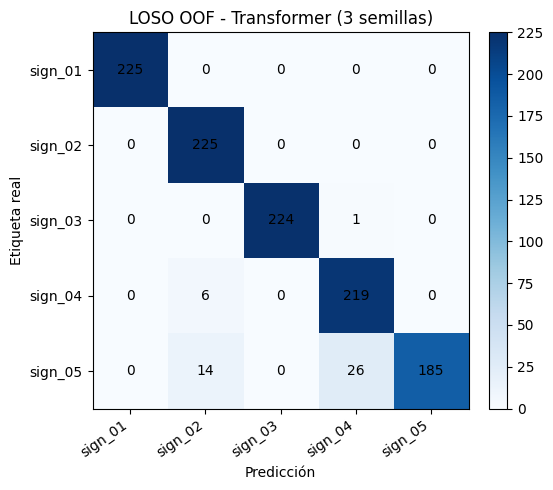

In [15]:
def evaluate_oof_ensemble(oof_by_seed, y_true, meta_df):
    P = np.mean(np.stack([oof_by_seed[s] for s in SEEDS]), axis=0)
    pred = P.argmax(axis=1)
    scores = calculate_metrics(y_true, pred)
    fold_rows = []
    signers = sorted(meta_df.signer.unique())
    for h in signers:
        mask = meta_df.signer.to_numpy() == h
        fold_rows.append({'heldout_signer': h, 'n_valid': int(mask.sum()),
                          **calculate_metrics(y_true[mask], pred[mask])})
    return P, pred, pd.DataFrame(fold_rows), scores

P, oof_pred, oof_folds, oof_scores = evaluate_oof_ensemble(oof_by_seed, y, metadata)
print('Accuracy OOF del Transformer (ensemble de semillas):', round(oof_scores['accuracy'], 6))
print('Macro-F1 OOF:', round(oof_scores['macro_f1'], 6))
print('Aciertos / total:', int((oof_pred == y).sum()), '/', len(y))
print('Peor fold:', round(oof_folds.accuracy.min(), 6))
print('Media accuracy por semilla:', round(all_results.groupby('seed').accuracy.mean().mean(), 6))
print('Std de medias por semilla:', round(all_results.groupby('seed').accuracy.mean().std(ddof=0), 6))
print('Resultados por fold:')
display(oof_folds)
print('Resultados por semilla/fold:')
display(all_results.pivot_table(index='seed', columns='heldout_signer', values='accuracy'))
print(classification_report(y, oof_pred, target_names=CLASS_NAMES, zero_division=0))
cm = print_confusion(y, oof_pred, 'LOSO OOF - Transformer (3 semillas)')

## 11. Auditoría de errores (participante × vista × seña)

Se guardan los errores OOF por participante/vista/clase; esto sirve para interpretar la generalización en las personas **públicas**. No utilizar el conjunto de test ni sus evaluaciones para ajustar el modelo. Después de varios cambios guiados por LOSO, pequeñas mejoras pueden estar sesgadas por selección.

In [16]:
def public_error_audit(meta_df, y_true, pred, probs):
    df = meta_df[['video_id', 'signer','view','label']].copy()
    df['predicted_sign'] = [ID_TO_CLASS[int(i)] for i in pred]
    df['correct'] = (pred == y_true)
    df['confidence'] = probs.max(axis=1)
    counts = df.groupby(['signer','view','label']).agg(n=('correct','size'), errors=('correct', lambda x: int((~x).sum())))
    counts['recall'] = 1 - counts['errors'] / counts['n']
    return df, counts.reset_index()

oof_details, errors_by_cell = public_error_audit(metadata, y, oof_pred, P)
print('Las 15 combinaciones más problemáticas (entrenamiento público):')
display(errors_by_cell.sort_values(['errors','recall'], ascending=[False, True]).head(15))
print('Errores de sign_05 por participante/vista:')
display(errors_by_cell.query("label == 'sign_05'").pivot(index='signer', columns='view', values='errors'))
wrong = np.stack([oof_by_seed[s].argmax(axis=1) != y for s in SEEDS])
print('Errores compartidos por las tres semillas:', int(wrong.all(axis=0).sum()))
print('Errores totales del ensemble:', int((oof_pred!=y).sum()))

Las 15 combinaciones más problemáticas (entrenamiento público):


,signer,view,label,n,errors,recall
19,M03,V01,sign_05,25,25,0.00
39,M04,V02,sign_05,25,14,0.44
43,M04,V03,sign_04,25,6,0.76
9,M02,V02,sign_05,25,1,0.96
22,M03,V02,sign_03,25,1,0.96
0,M02,V01,sign_01,25,0,1.00
1,M02,V01,sign_02,25,0,1.00
2,M02,V01,sign_03,25,0,1.00
3,M02,V01,sign_04,25,0,1.00
4,M02,V01,sign_05,25,0,1.00


Errores de sign_05 por participante/vista:


view,V01,V02,V03
signer,,,
M02,0,1,0
M03,25,0,0
M04,0,14,0


Errores compartidos por las tres semillas: 41
Errores totales del ensemble: 47


## 12. Guardar métricas, probabilidades OOF y configuración

No se copian salidas anteriores de T9. Este notebook guarda **solamente los resultados que acaba de producir** en un directorio independiente por variante/configuración.

In [17]:
all_results.to_csv(OUT_DIR / 'loso_transformer_per_seed_fold.csv', index=False)
oof_folds.to_csv(OUT_DIR / 'loso_transformer_ensemble_folds.csv', index=False)
oof_details.to_csv(OUT_DIR / 'oof_predictions_public.csv', index=False)
errors_by_cell.to_csv(OUT_DIR / 'public_errors_signer_view_class.csv', index=False)
np.save(OUT_DIR / 'oof_proba_transformer_mean.npy', P)
np.save(OUT_DIR / 'oof_proba_transformer_by_seed.npy', np.stack([oof_by_seed[s] for s in SEEDS]))
metadata.to_csv(OUT_DIR / 'train_metadata.csv', index=False)
selected_epochs = {str(s): [int(e) for e in epochs_by_seed[s]] for s in SEEDS}
with open(OUT_DIR / 'selected_epochs.json', 'w', encoding='utf-8') as f:
    json.dump({'folds_order': sorted(metadata.signer.unique()), 'epochs': selected_epochs}, f, indent=2)
with open(OUT_DIR / 'experiment_config.json', 'w', encoding='utf-8') as f:
    json.dump({**CFG, 'config_tag': CFG_TAG, 'dataset_train_dir': str(TRAIN_LANDMARKS_DIR),
               'n_train': int(len(metadata)), 'classes': CLASS_NAMES,
               'oof_accuracy': oof_scores['accuracy'], 'oof_macro_f1': oof_scores['macro_f1'],
               'oof_worst_fold': float(oof_folds.accuracy.min()),
               'oof_sign05_recall': float(((oof_pred == 4) & (y == 4)).sum() / max(1,(y==4).sum()))},
              f, indent=2, ensure_ascii=False)
print('Artefactos de validación guardados en:', OUT_DIR)

# Comparador local de experimentos completados. NO lee test ni usa sus resultados.
def compare_previous_t10_runs(root=OUT_DIR.parent):
    rows = []
    for p in sorted(Path(root).glob('lsc5_t10_transformer_*/experiment_config.json')):
        try:
            d = json.loads(p.read_text(encoding='utf-8'))
            rows.append({'directorio': p.parent.name, 'modo': d.get('preprocess_mode'),
                         'mascaras': d.get('presence_mask_mode'),
                         'gap': d.get('max_interpolation_gap'), 'accuracy': d.get('oof_accuracy'),
                         'macro_f1': d.get('oof_macro_f1'), 'peor_fold': d.get('oof_worst_fold'),
                         'recall_sign05': d.get('oof_sign05_recall'),
                         'quick_test': d.get('quick_test', False)})
        except (ValueError, OSError):
            pass
    return pd.DataFrame(rows)

print('Comparación de corridas de T10 guardadas (NO usar QUICK_TEST para decidir):')
display(compare_previous_t10_runs())

Artefactos de validación guardados en: /kaggle/working/lsc5_t10_transformer_mask_aware_ba4092f8db67
Comparación de corridas de T10 guardadas (NO usar QUICK_TEST para decidir):


,directorio,modo,mascaras,gap,accuracy,macro_f1,peor_fold,recall_sign05,quick_test
0,lsc5_t10_transformer_mask_aware_ba4092f8db67,mask_aware,keep,3,0.958222,0.957519,0.930667,0.822222,False


## 13. Comparación de preprocesamientos: cómo interpretarla

**Este notebook no inventa una mejora.** Para contrastar, se requieren dos ejecuciones completas con configuración idéntica, cambiando **solo** `PREPROCESS_MODE`:

- `legacy`: mismo preprocesamiento original de T9. Debe estar cercano al 95,64 % publicado (no necesariamente idéntico entre entornos GPU).
- `mask_aware`: presencia cruda, imputación de huecos cortos y remuestreo que evita mezclas con ausencias.
- **Ablación opcional después**: mantener `mask_aware` y cambiar `PRESENCE_MASK_MODE` de `'keep'` a `'drop_hands'`, que elimina SOLO canales de presencia de manos sin modificar la arquitectura. También se puede comparar `MAX_INTERPOLATION_GAP=0` frente a `3`, cambiando una variable por corrida.

Guardar las carpetas de las dos corridas y comparar: accuracy general, accuracy del peor firmante, recall de `sign_05`, diferencias por vista y errores comunes entre semillas. Para diferencias pequeñas considerar ruido por semillas y selección previa; M01 **no** debe consultarse para elegir. Si el nuevo preprocesamiento no mejora de manera convincente, mantener el T9 original.

## 14. Entrenamiento definitivo opcional con los tres participantes públicos

**Requiere `TRAIN_FINAL_MODEL=True`.** Se usa la mediana de las épocas LOSO interiores y se entrena cada semilla desde cero con los **tres participantes públicos** y sus muestras espejadas. No se entrena ningún otro modelo. Los pesos y escaladores se guardan como tensores para que sean cargables con `weights_only=True`.

In [18]:
FINAL_EPOCHS = max(1, int(np.median([e for s in SEEDS for e in epochs_by_seed[s]])))
print('Épocas finales elegidas exclusivamente con LOSO interno:', FINAL_EPOCHS)
final_models = []

def save_checkpoint(model, scaler, seed, path):
    payload = {
        'model_state_dict': {k: v.detach().cpu() for k, v in model.state_dict().items()},
        'scaler_mean': torch.as_tensor(scaler['mean'].copy()),
        'scaler_std': torch.as_tensor(scaler['std'].copy()),
        'config': {'model': 'transformer', 'seed': int(seed), 'seq_len': SEQ_LEN,
                   'input_dim': INPUT_DIM, 'use_436': USE_436, 'preprocess_mode': PREPROCESS_MODE,
                   'preprocess_version': PREPROCESS_VERSION, 'max_interpolation_gap': MAX_INTERPOLATION_GAP,
                   'final_epochs': FINAL_EPOCHS, 'mirror_aug': MIRROR_AUG,
                   'mirror_tta': MIRROR_TTA, 'classes': CLASS_NAMES,
                   'arch': {'d_model': D_MODEL, 'n_layers': N_LAYERS, 'n_heads': N_HEADS,
                            'ffn_dim': FFN_DIM, 'dropout': DROPOUT}}
    }
    torch.save(payload, path)


def load_checkpoint(path):
    """Carga solo checkpoints propios de T10 guardados como tensores y tipos básicos."""
    try:
        ckp = torch.load(path, map_location='cpu', weights_only=True)
    except TypeError:
        ckp = torch.load(path, map_location='cpu')  # PyTorch anterior a weights_only
    conf = ckp['config']
    for k, expected in [('preprocess_mode', PREPROCESS_MODE), ('preprocess_version', PREPROCESS_VERSION),
                        ('seq_len', SEQ_LEN), ('input_dim', INPUT_DIM), ('use_436', USE_436),
                        ('max_interpolation_gap', MAX_INTERPOLATION_GAP), ('mirror_tta', MIRROR_TTA)]:
        if conf[k] != expected:
            raise ValueError(f'Checkpoint incompatible: {k}={conf[k]} vs {expected}')
    model = make_model().to(DEVICE)
    model.load_state_dict(ckp['model_state_dict'])
    model.eval()
    scaler = {'mean': ckp['scaler_mean'].numpy().astype(np.float32),
              'std': ckp['scaler_std'].numpy().astype(np.float32)}
    return model, scaler, conf

if TRAIN_FINAL_MODEL:
    X_final = np.concatenate([X, X_mirror]) if MIRROR_AUG else X
    y_final = np.concatenate([y, y]) if MIRROR_AUG else y
    for s in SEEDS:
        net, scaler, _, history = fit_model('transformer', X_final, y_final,
                                             max_epochs=FINAL_EPOCHS, patience=FINAL_EPOCHS,
                                             seed=s + 999)
        ckpt_path = OUT_DIR / f'lsc5_transformer_final_seed{s}.pt'
        save_checkpoint(net, scaler, s, ckpt_path)
        history.to_csv(OUT_DIR / f'final_training_history_seed{s}.csv', index=False)
        reloaded, loaded_scaler, _ = load_checkpoint(ckpt_path)
        # Verificación de igualdad de probabilidades en 3 muestras públicas.
        reference = predict_proba(net, scaler, X[:3], X_mirror[:3])
        recovered = predict_proba(reloaded, loaded_scaler, X[:3], X_mirror[:3])
        assert np.allclose(reference, recovered, atol=1e-5), 'Carga del checkpoint cambió las predicciones'
        final_models.append((reloaded, loaded_scaler))
        print('Guardado y recargado OK:', ckpt_path.name)
        del net
    print('Checkpoints finales:', len(final_models))
else:
    print('Entrenamiento final deshabilitado; habilitar solo tras comparar las variantes LOSO.')

Épocas finales elegidas exclusivamente con LOSO interno: 32
Guardado y recargado OK: lsc5_transformer_final_seed42.pt
Guardado y recargado OK: lsc5_transformer_final_seed7.pt
Guardado y recargado OK: lsc5_transformer_final_seed123.pt
Checkpoints finales: 3


## 15. Inferencia final opcional — test únicamente para inferencia

**Seguridad:** para activar la inferencia debes fijar `RUN_FINAL_TEST_INFERENCE=True` **y** disponer de los checkpoints propios correspondientes a la variante escogida. Solo se permite transformar cada muestra individual y predecir: está prohibido entrenar, adaptar o seleccionar hiperparámetros usando test. El código solo lee la plantilla y los `.npy` del test dentro de esta celda opcional.

In [19]:
def discover_test_landmarks(root=DATA_ROOT, override=None):
    if override is not None:
        p = Path(override)
        if not p.exists(): raise FileNotFoundError(p)
        return p
    folders = [p for p in root.rglob('landmarks') if p.is_dir() and
               'test' in [part.lower() for part in p.parts] and any(p.rglob('*.npy'))]
    if not folders: raise FileNotFoundError('No encontré test/landmarks; usa TEST_LANDMARKS_DIR.')
    return sorted(folders, key=lambda p: len(str(p)))[0]


def build_test_features(test_dir):
    paths = sorted(Path(test_dir).rglob('*.npy'))
    if not paths: raise FileNotFoundError('Sin .npy para inferencia')
    ids, feats, mirrored = [], [], []
    for p in tqdm(paths, desc='Inferencia individual de test'):
        raw = load_landmark_array(p)
        ids.append(p.stem)
        feats.append(full_features(raw, SEQ_LEN, PREPROCESS_MODE))
        mirrored.append(full_features(mirror_raw(raw), SEQ_LEN, PREPROCESS_MODE))
    return ids, np.stack(feats), np.stack(mirrored)


def predict_with_checkpoints(X_raw, X_mir, checkpoint_dir=OUT_DIR):
    paths = [Path(checkpoint_dir) / f'lsc5_transformer_final_seed{s}.pt' for s in SEEDS]
    if not all(p.exists() for p in paths):
        raise FileNotFoundError('Faltan checkpoints finales. Deben ser de la misma variante y 3 semillas.')
    probs = []
    for path in paths:
        model, scaler, _ = load_checkpoint(path)
        probs.append(predict_proba(model, scaler, X_raw, X_mir))
        del model
    return np.stack(probs).mean(axis=0)


def generate_submission(test_dir, out_dir=OUT_DIR, template_path=SUBMISSION_TEMPLATE_PATH):
    ids, Xt, Xm = build_test_features(test_dir)
    if len(set(ids)) != len(ids): raise RuntimeError('Hay IDs duplicados en test.')
    probs = predict_with_checkpoints(Xt, Xm)
    labels = [ID_TO_CLASS[int(i)] for i in probs.argmax(axis=1)]
    sub = pd.DataFrame({'video_id': ids, 'predicted_sign': labels})
    template_files = [Path(template_path)] if template_path else list(DATA_ROOT.rglob('submission_template.csv'))
    if template_files:
        tmpl = pd.read_csv(template_files[0])
        if 'video_id' not in tmpl or tmpl['video_id'].duplicated().any():
            raise RuntimeError('Plantilla inválida o IDs repetidos.')
        if set(tmpl['video_id']) != set(sub['video_id']):
            raise RuntimeError('IDs de test y plantilla distintos: no generar CSV incompleto.')
        sub = tmpl[['video_id']].merge(sub, on='video_id', how='left', validate='one_to_one')
    if sub.isna().any().any() or not sub['predicted_sign'].isin(CLASS_NAMES).all():
        raise RuntimeError('CSV contiene valores faltantes o clases desconocidas.')
    if len(sub) != 375:
        warnings.warn(f'El manual espera 375 videos de test; hay {len(sub)}. Verificar paquete.')
    path = Path(out_dir) / 'submission.csv'
    sub.to_csv(path, index=False, encoding='utf-8')
    print('Predicciones finales generadas:', path, '| filas:', len(sub))
    return sub

if RUN_FINAL_TEST_INFERENCE:
    if QUICK_TEST: raise RuntimeError('No generar inferencia final desde QUICK_TEST')
    TEST_LANDMARKS_DIR = discover_test_landmarks(DATA_ROOT, TEST_LANDMARKS_DIR)
    submission = generate_submission(TEST_LANDMARKS_DIR)
else:
    print('Inferencia oficial desactivada: NO se ha leído ningún archivo de test.')

Inferencia oficial desactivada: NO se ha leído ningún archivo de test.


## 16. Empaquetado de resultados y checklist final

No se añaden archivos de datos a la exportación, solo métricas, predicciones OOF (datos públicos), y checkpoints si se entrenaron. **No distribuir OOF o artefactos si su publicación viola las condiciones del dataset**.

- [ ] Modo `legacy` corrido (control) y comparado contra T9.
- [ ] Modo `mask_aware` corrido con las mismas semillas e hiperparámetros.
- [ ] Interpretar variaciones pequeñas con prudencia: ya se eligió la familia Transformer analizando LOSO múltiples veces.
- [ ] Verificado `sign_05` por clase, persona y vista; no escoger variantes usando test.
- [ ] Si hay una mejora robusta, entrenar con `TRAIN_FINAL_MODEL=True` y conservar los tres pesos.
- [ ] Verificar carga de checkpoints en un kernel limpio, con el preprocesamiento **correspondiente**.
- [ ] Congelar la solución antes de ejecutar test. Generar exactamente los `video_id` de la plantilla.
- [ ] No incluir dataset externo no autorizado ni exponer videos/landmarks de personas.
- [ ] Registrar semillas, commit, métricas y versiones en reporte técnico.

In [20]:
import zipfile

def package_artifacts(out_dir=OUT_DIR):
    out_dir = Path(out_dir)
    zip_path = out_dir.parent / f'{out_dir.name}_artifacts.zip'
    with zipfile.ZipFile(zip_path, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        for p in sorted(out_dir.rglob('*')):
            if p.is_file():
                z.write(p, arcname=p.relative_to(out_dir))
    return zip_path

archive = package_artifacts()
print('ZIP de artefactos:', archive)
print('Total archivos en la carpeta:', len(list(OUT_DIR.glob('*'))))

ZIP de artefactos: /kaggle/working/lsc5_t10_transformer_mask_aware_ba4092f8db67_artifacts.zip
Total archivos en la carpeta: 16
